# Mision 1

In [ ]:
%pip install -q osmnx==2.0.7 networkx==3.4.2 geopandas==1.1.4 shapely==2.1.2 folium==0.20.0 mapclassify==2.8.1 scipy matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pysal 25.7 requires mapclassify>=2.10.0, but you have mapclassify 2.8.1 which is incompatible.


Importar modulos y data sets genericos

In [171]:
import geopandas as gpd, pandas as pd, numpy as np
import osmnx as ox, networkx as nx, folium

CRS_METROS = "EPSG:32719"
CRS_GRADOS = "EPSG:4326"

base = "/content/drive/MyDrive/datos_geoespaciales/"
distritos  = gpd.read_file(base + "Distritos Censales/Distritos Censales RM.shp").to_crs(32719)
centroides = gpd.read_file(base + "Distritos Censales/centroides Distritos Censales RM.shp").to_crs(32719)
estaciones = gpd.read_file(base + "Metro 2020/Estaciones_2020/Estaciones_2020.shp").to_crs(32719)
lineas     = gpd.read_file(base + "Metro 2020/Lineas_2020/Lineas_2020.shp").to_crs(32719)
comunas    = gpd.read_file(base + "Comunas/comunas.shp").to_crs(32719)
atropellos = gpd.read_file(base + "Accidentes/Atropellos_2020.geojson").to_crs(32719)


In [183]:
est_cen = comunas[comunas["Comuna"] == "Estación Central"]
centroide = centroides[centroides["NOM_DIS"] == "Estación Central"]
centroide = centroide.geometry.to_crs(CRS_GRADOS)

Importar data set especifico
Se elgige estacion central para la mision 1

In [155]:
est_cen_drive = ox.load_graphml(base + "redes/estación_central_drive.graphml.xml")
est_cen_walk = ox.load_graphml(base + "redes/estación_central_walk.graphml.xml")

Visualizar uno de los data sets a utilizar

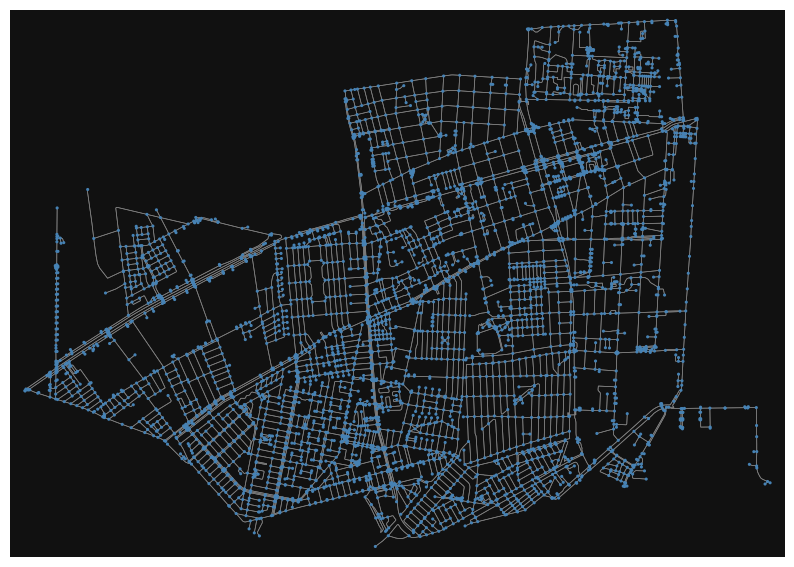

In [111]:

fig, ax = ox.plot_graph(est_cen_walk, node_size=5, node_color="steelblue",
                        edge_color="gray", edge_linewidth=0.5,
                        figsize=(10, 10))

Funcion cambio de coordenadas a crs para varios puntos a la vez

In [156]:


estaciones_est_cen = gpd.overlay(estaciones.to_crs(CRS_METROS), est_cen.to_crs(CRS_METROS), how="union")
estaciones_est_cen.dropna()

def cambiocoord(geom):
  geom = geom.to_crs(CRS_GRADOS)
  return([list(geom.x),list(geom.y)])

est_coord = cambiocoord(estaciones_est_cen.geometry)


In [184]:
o = ox.nearest_nodes(est_cen_drive, X=est_coord[0][0], Y=est_coord[0][1])
d = ox.nearest_nodes(est_cen_drive, X=centroide.x, Y=centroide.y)

print(centroide.x)

62   -70.682519
dtype: float64


# MISION 2

In [127]:
estaciones = estaciones.to_crs(CRS_METROS)
metro_est_cen = estaciones[ estaciones["ESTACION"]=="ESTACION CENTRAL" ]
metro_uni_san = estaciones[ estaciones["ESTACION"]=="UNIVERSIDAD DE SANTIAGO" ]

metro_est_cen_g = metro_est_cen.geometry.to_crs(CRS_GRADOS)
metro_uni_san_g = metro_uni_san.geometry.to_crs(CRS_GRADOS)


In [130]:
id_m_est_cen = ox.nearest_nodes(est_cen_walk, X=metro_est_cen_g.x.iloc[0], Y=metro_est_cen_g.y.iloc[0])
id_m_uni_san = ox.nearest_nodes(est_cen_walk, X=metro_uni_san_g.x.iloc[0], Y=metro_uni_san_g.y.iloc[0])

largo_metros = nx.shortest_path_length(est_cen_walk, id_m_est_cen, id_m_uni_san, weight="length")

In [166]:
# Convertir 4.5 km/h a m/s -> 4.5 / 3.6 = 1.25 m/s
v_caminata_ms = 4.5 / 3.6  # 1.25 m/s

# Tiempo en segundos y minutos
tiempo_segundos = largo_metros / v_caminata_ms
tiempo_minutos = tiempo_segundos / 60

print("Caminando")
print(largo_metros)
print(tiempo_minutos)

print("Euclidiana")
distancia_lineal = np.sqrt((metro_est_cen.geometry.x.iloc[0] - metro_uni_san.geometry.x.iloc[0])**2 + (metro_est_cen.geometry.y.iloc[0] - metro_uni_san.geometry.y.iloc[0]))
print(distancia_lineal)

tiempo_lineal = distancia_lineal /v_caminata_ms / 60
print(tiempo_lineal)

print("Factor de bloqueo")
print(largo_metros/distancia_lineal)



Caminando
808.0512865061974
10.774017153415965
Euclidiana
739.5177161303511
9.860236215071348
Factor de bloqueo
1.0926733313901653


El factor de bloqueo de 1.09 en ciudad es bajo este valor puede llegar hasta 1.4 cuando existen bloqueos importantes como rios cruces ferroviarios etc.

/tmp/ipykernel_1731/4275789780.py:6: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  ax = est_cen.plot(figsize = (10,10))


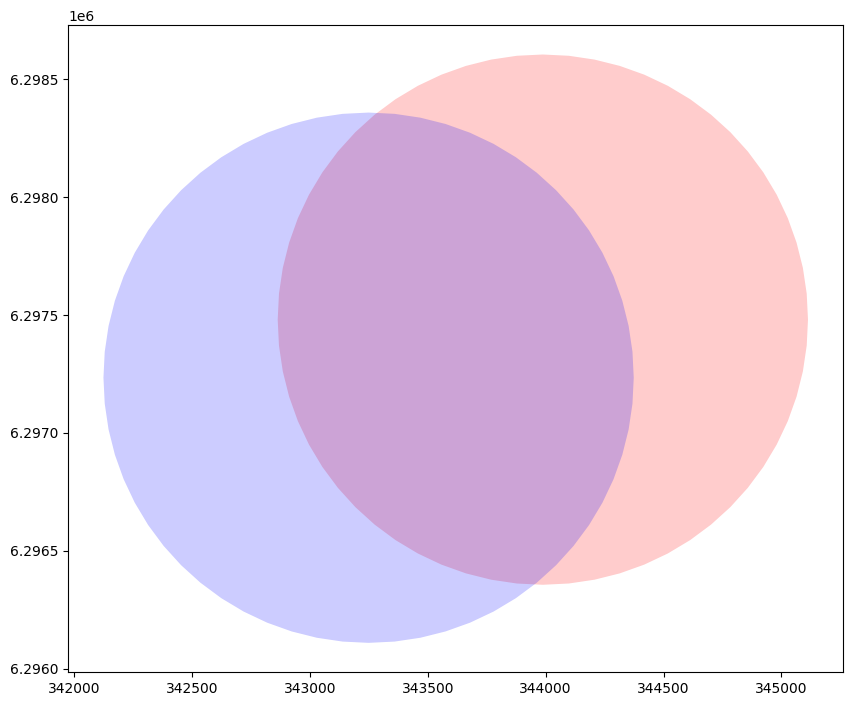

In [167]:
distancia_razonable = 1.25* 15 * 60
buffer1 = metro_est_cen.geometry.buffer(distancia_razonable)
buffer2 = metro_uni_san.geometry.buffer(distancia_razonable)

# Guardamos nuestro primer gráfico en una variable
ax = est_cen.plot(figsize = (10,10))

# Usamos esa variable (que es un axes) y construímos el segundo gráfico con el anterior como base
# Es importante que le cambiemos el color para que se puedan visualizar sin problemas.
ax1 = buffer1.plot(ax = ax, figsize = (10,10), color = 'red', alpha = 0.2);
buffer2.plot(ax = ax1, figsize = (10,10), color = 'blue', alpha = 0.2);


